In [46]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import math
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path

In [47]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", device)

Dispositivo: cuda


In [48]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2

        frequencies = math.log(10000) / (half_dim - 1)

        frequencies = torch.exp(
            torch.arange(
                half_dim,
                device=t.device
            ) * -frequencies
        )

        angles = t.float()[:, None] * frequencies[None, :]

        embedding = torch.cat(
            [angles.sin(), angles.cos()],
            dim=1
        )

        return embedding

time_embedding = SinusoidalTimeEmbedding(64).to(device)

test_t = torch.tensor(
    [0, 100, 300, 999],
    device=device
)

emb = time_embedding(test_t)

In [49]:
class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.norm1 = nn.GroupNorm(
            8,
            out_channels
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.norm2 = nn.GroupNorm(
            8,
            out_channels
        )

        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_dim, out_channels)
        )

        if in_channels != out_channels:
            self.residual = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )
        else:
            self.residual = nn.Identity()

    def forward(self, x, t_emb):

        h = self.conv1(x)
        h = self.norm1(h)
        h = F.silu(h)

        time_information = self.time_mlp(t_emb)
        time_information = time_information[:, :, None, None]

        h = h + time_information

        h = self.conv2(h)
        h = self.norm2(h)

        h = h + self.residual(x)

        return F.silu(h)

# Mini U-Net

class SimpleUNet(nn.Module):
    def __init__(self, time_dim=64):
        super().__init__()

        # Embedding temporal
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        # Entrada: 1 canal (MNIST)
        self.input_conv = nn.Conv2d(
            1,
            64,
            kernel_size=3,
            padding=1
        )

        # Encoder
        self.block1 = ResBlock(
            64,
            64,
            time_dim
        )

        self.down1 = nn.Conv2d(
            64,
            128,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.block2 = ResBlock(
            128,
            128,
            time_dim
        )

        self.down2 = nn.Conv2d(
            128,
            256,
            kernel_size=4,
            stride=2,
            padding=1
        )

        # Parte más profunda
        self.middle = ResBlock(
            256,
            256,
            time_dim
        )

        # Decoder
        self.up1 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.block3 = ResBlock(
            256,
            128,
            time_dim
        )

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=4,
            stride=2,
            padding=1
        )

        self.block4 = ResBlock(
            128,
            64,
            time_dim
        )

        # Salida: ruido predicho
        self.output_conv = nn.Conv2d(
            64,
            1,
            kernel_size=1
        )

    def forward(self, x, t):

        t_emb = self.time_embedding(t)

        # Entrada
        x = self.input_conv(x)

        # Encoder
        skip1 = self.block1(x, t_emb)

        x = self.down1(skip1)

        skip2 = self.block2(x, t_emb)

        x = self.down2(skip2)

        # Centro
        x = self.middle(x, t_emb)

        # Decoder
        x = self.up1(x)

        x = torch.cat(
            [x, skip2],
            dim=1
        )

        x = self.block3(x, t_emb)

        x = self.up2(x)

        x = torch.cat(
            [x, skip1],
            dim=1
        )

        x = self.block4(x, t_emb)

        return self.output_conv(x)

In [50]:
T = 1000

betas = torch.linspace(
    1e-4,
    0.02,
    T,
    device=device
)

alphas = 1.0 - betas

alpha_bar = torch.cumprod(
    alphas,
    dim=0
)

In [51]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5,),
        (0.5,)
    )
])

dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=False,
    transform=transform
)

loader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=True
)

print("MNIST cargado.")

MNIST cargado.


In [52]:
# ============================================================
# 1. ASEGURAR QUE EL MODELO ESTÉ EN MODO EVALUACIÓN
# ============================================================

model = SimpleUNet().to(device)

model.load_state_dict(
    torch.load(
        "modelos/mnist_diffusion_model.pt",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Modelo cargado correctamente.")


Modelo cargado correctamente.


In [53]:
print(
    "Primer parámetro:",
    next(model.parameters())
        .flatten()[:5]
        .detach()
        .cpu()
)

print(
    "Número de parámetros:",
    sum(
        p.numel()
        for p in model.parameters()
    )
)

print(
    "betas:",
    betas[0].item(),
    betas[-1].item()
)

print(
    "alpha_bar final:",
    alpha_bar[-1].item()
)

Primer parámetro: tensor([ 0.0967,  0.1149,  0.0173, -0.1024,  0.0760])
Número de parámetros: 3508161
betas: 9.999999747378752e-05 0.019999999552965164
alpha_bar final: 4.035829260828905e-05


Dígito real: 0
Shape x0: torch.Size([1, 1, 28, 28])


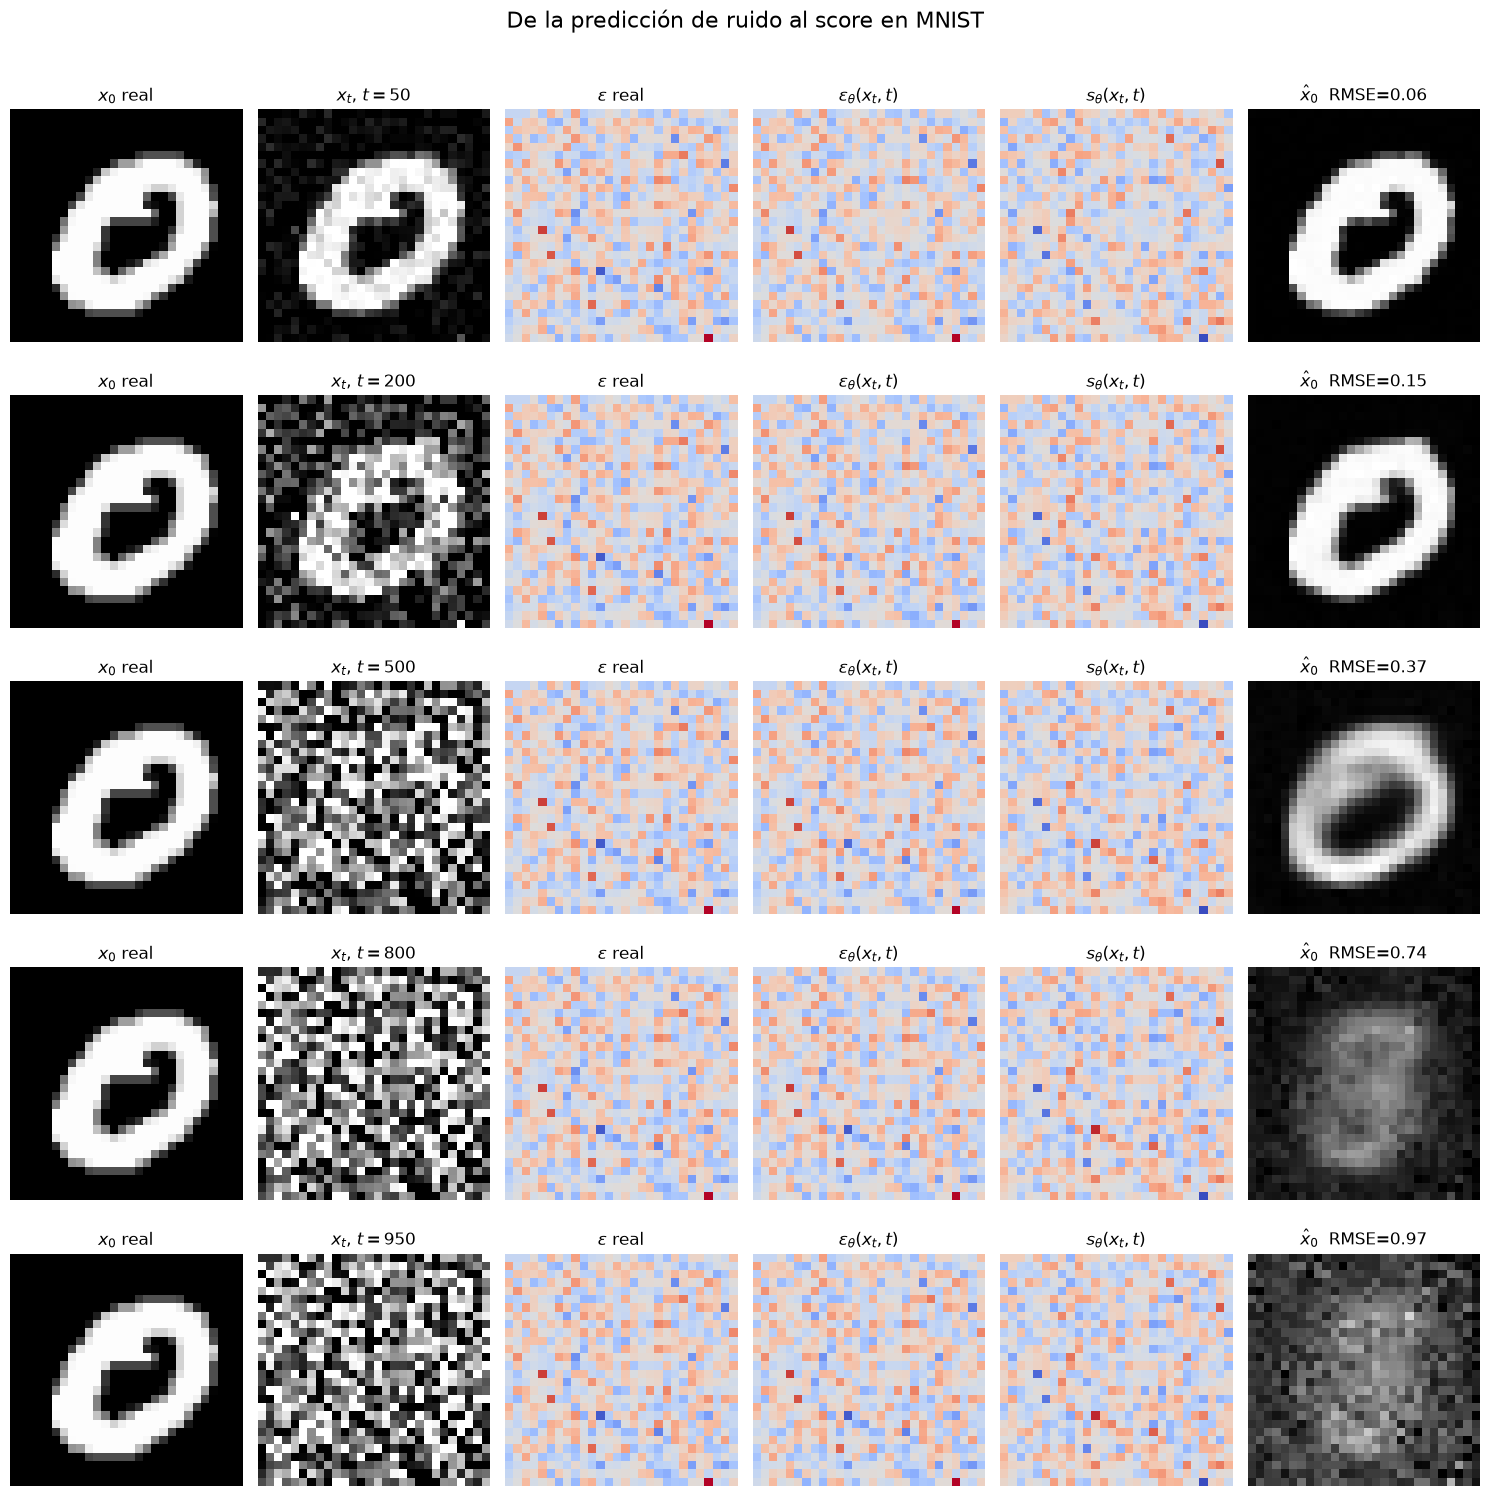

In [54]:
# ============================================================
# 2. TOMAR UNA IMAGEN DE MNIST
# ============================================================

x0_batch, labels = next(iter(loader))

x0 = x0_batch[0:1].to(device)

label = labels[0].item()

print("Dígito real:", label)
print("Shape x0:", x0.shape)


# ============================================================
# 3. TIEMPOS QUE QUEREMOS VISUALIZAR
# ============================================================

t_values = [
    50,
    200,
    500,
    800,
    950
]


# ============================================================
# 4. FUNCIÓN PARA EXTRAER alpha_bar_t
# ============================================================

def get_alpha_bar(t, batch_size=1):

    t_tensor = torch.full(
        (batch_size,),
        t,
        dtype=torch.long,
        device=device
    )

    abar = alpha_bar[t_tensor]

    return abar.view(
        batch_size,
        1,
        1,
        1
    )

# ============================================================
# 5. GENERAR RESULTADOS
#
# Usaremos EXACTAMENTE el mismo ruido epsilon
# para todos los valores de t.
# ============================================================

# Una sola realización del ruido
epsilon_shared = torch.randn_like(x0)

results = []


for t in t_values:

    # --------------------------------------------------------
    # Tiempo como tensor
    # --------------------------------------------------------

    t_tensor = torch.full(
        (1,),
        t,
        dtype=torch.long,
        device=device
    )


    # --------------------------------------------------------
    # alpha_bar_t
    # --------------------------------------------------------

    abar = get_alpha_bar(t)


    # --------------------------------------------------------
    # Construir x_t
    #
    # IMPORTANTE:
    # el mismo epsilon_shared se utiliza en todas las filas
    # --------------------------------------------------------

    xt = (
        torch.sqrt(abar) * x0
        +
        torch.sqrt(1.0 - abar) * epsilon_shared
    )


    # --------------------------------------------------------
    # Predicción de ruido de la U-Net
    # --------------------------------------------------------

    with torch.no_grad():

        epsilon_pred = model(
            xt,
            t_tensor
        )


    # ========================================================
    # 6. SCORE ESTIMADO
    #
    # s_theta(x_t,t)
    # =
    # - epsilon_theta / sqrt(1-alpha_bar_t)
    # ========================================================

    score_pred = (
        -epsilon_pred
        /
        torch.sqrt(
            1.0 - abar
        )
    )


    # ========================================================
    # 7. ESTIMACIÓN DE x_0
    # ========================================================

    x0_hat = (
        xt
        -
        torch.sqrt(
            1.0 - abar
        )
        *
        epsilon_pred
    ) / torch.sqrt(abar)


    # --------------------------------------------------------
    # Error de reconstrucción respecto a x0
    # --------------------------------------------------------

    rmse = torch.sqrt(
        torch.mean(
            (x0_hat - x0) ** 2
        )
    ).item()


    # --------------------------------------------------------
    # Guardar resultados
    # --------------------------------------------------------

    results.append({
        "t": t,
        "xt": xt.detach().cpu(),
        "epsilon": epsilon_shared.detach().cpu(),
        "epsilon_pred": epsilon_pred.detach().cpu(),
        "score": score_pred.detach().cpu(),
        "x0_hat": x0_hat.detach().cpu(),
        "rmse": rmse
    })


# ============================================================
# 8. FUNCIÓN PARA x0 Y xt
# ============================================================

def show_mnist(ax, tensor, title):

    image = tensor.squeeze().numpy()

    ax.imshow(
        image,
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    ax.set_title(title)

    ax.axis("off")


# ============================================================
# 9. FUNCIÓN PARA epsilon Y SCORE
# ============================================================

def show_signed(ax, tensor, title):

    image = tensor.squeeze().numpy()

    max_abs = np.max(
        np.abs(image)
    )

    if max_abs < 1e-8:
        max_abs = 1.0

    ax.imshow(
        image,
        cmap="coolwarm",
        vmin=-max_abs,
        vmax=max_abs
    )

    ax.set_title(title)

    ax.axis("off")


# ============================================================
# 10. FUNCIÓN ESPECIAL PARA x0_hat
#
# Aquí NO hacemos clip a [-1,1].
# Esto evita que para t grandes la imagen quede
# artificialmente binaria.
# ============================================================

def show_x0_hat(ax, tensor, title):

    image = tensor.squeeze().numpy()

    # Escala robusta:
    # ignoramos unos pocos valores extremos
    scale = np.percentile(
        np.abs(image),
        98
    )

    if scale < 1e-8:
        scale = 1.0

    ax.imshow(
        image,
        cmap="gray",
        vmin=-scale,
        vmax=scale
    )

    ax.set_title(title)

    ax.axis("off")


# ============================================================
# 11. FIGURA
# ============================================================

n_rows = len(results)

n_cols = 6


fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 3 * n_rows)
)


for i, result in enumerate(results):

    t = result["t"]

    rmse = result["rmse"]


    # --------------------------------------------------------
    # x0 real
    # --------------------------------------------------------

    show_mnist(
        axes[i, 0],
        x0.cpu(),
        r"$x_0$ real"
    )


    # --------------------------------------------------------
    # x_t
    # --------------------------------------------------------

    show_mnist(
        axes[i, 1],
        result["xt"],
        rf"$x_t$, $t={t}$"
    )


    # --------------------------------------------------------
    # epsilon real
    #
    # Esta columna será IGUAL en todas las filas
    # --------------------------------------------------------

    show_signed(
        axes[i, 2],
        result["epsilon"],
        r"$\epsilon$ real"
    )


    # --------------------------------------------------------
    # epsilon predicho
    # --------------------------------------------------------

    show_signed(
        axes[i, 3],
        result["epsilon_pred"],
        r"$\epsilon_\theta(x_t,t)$"
    )


    # --------------------------------------------------------
    # score estimado
    # --------------------------------------------------------

    show_signed(
        axes[i, 4],
        result["score"],
        r"$s_\theta(x_t,t)$"
    )


    # --------------------------------------------------------
    # x0 estimado
    # --------------------------------------------------------

    show_x0_hat(
        axes[i, 5],
        result["x0_hat"],
        rf"$\hat{{x}}_0$  RMSE={rmse:.2f}"
    )


plt.suptitle(
    "De la predicción de ruido al score en MNIST",
    fontsize=16,
    y=1.01
)


plt.tight_layout()

plt.show()

In [55]:
@torch.no_grad()
def sample_reverse(model, n_samples=1):

    model.eval()

    # Ruido gaussiano inicial
    x = torch.randn(
        n_samples,
        1,
        28,
        28,
        device=device
    )

    snapshots = {}

    save_times = [
        999,
        800,
        600,
        400,
        200,
        50,
        0
    ]

    for timestep in reversed(range(T)):

        t = torch.full(
            (n_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )

        # Predicción de ruido
        predicted_noise = model(
            x,
            t
        )

        beta_t = betas[timestep]
        alpha_t = alphas[timestep]
        alpha_bar_t = alpha_bar[timestep]

        # Media reverse
        mean = (
            1 / torch.sqrt(alpha_t)
        ) * (
            x
            -
            beta_t
            / torch.sqrt(1 - alpha_bar_t)
            * predicted_noise
        )

        if timestep > 0:

            alpha_bar_previous = alpha_bar[
                timestep - 1
            ]

            posterior_variance = (
                beta_t
                * (1 - alpha_bar_previous)
                / (1 - alpha_bar_t)
            )

            z = torch.randn_like(x)

            x = (
                mean
                +
                torch.sqrt(
                    posterior_variance
                )
                * z
            )

        else:

            x = mean

        if timestep in save_times:

            snapshots[timestep] = (
                x.detach()
                .cpu()
                .clone()
            )

    return x, snapshots

In [56]:
"""
# ============================================================
# REVERSE DDPM - VERSIÓN ESTABLE
# ============================================================

model.eval()

torch.manual_seed(42)

# Empezamos desde ruido puro
x = torch.randn(
    1, 1, 28, 28,
    device=device
)

steps_to_save = [
    999,
    800,
    600,
    400,
    200,
    50,
    0
]

snapshots = {}

# Guardamos el ruido inicial
snapshots[999] = x.detach().cpu().clone()


with torch.no_grad():

    for t in reversed(range(T)):

        # ----------------------------------------------------
        # Tiempo
        # ----------------------------------------------------

        t_tensor = torch.full(
            (1,),
            t,
            dtype=torch.long,
            device=device
        )

        beta_t = betas[t]
        alpha_t = alphas[t]
        alpha_bar_t = alpha_bar[t]


        # ----------------------------------------------------
        # alpha_bar del paso anterior
        # ----------------------------------------------------

        if t > 0:

            alpha_bar_prev = alpha_bar[t - 1]

        else:

            alpha_bar_prev = torch.tensor(
                1.0,
                device=device
            )


        # ----------------------------------------------------
        # 1. Predecir el ruido
        # ----------------------------------------------------

        epsilon_pred = model(
            x,
            t_tensor
        )


        # ----------------------------------------------------
        # 2. Estimar x0
        # ----------------------------------------------------

        x0_pred = (
            x
            -
            torch.sqrt(
                1.0 - alpha_bar_t
            )
            *
            epsilon_pred
        ) / torch.sqrt(
            alpha_bar_t
        )


        # ----------------------------------------------------
        # IMPORTANTE:
        # MNIST fue normalizado a [-1, 1]
        #
        # Esto evita que errores pequeños exploten
        # durante la cadena inversa.
        # ----------------------------------------------------

        x0_pred = torch.clamp(
            x0_pred,
            -1.0,
            1.0
        )


        # ----------------------------------------------------
        # 3. Media posterior
        #
        # q(x_{t-1}|x_t,x0)
        # ----------------------------------------------------

        coef_x0 = (
            beta_t
            *
            torch.sqrt(alpha_bar_prev)
            /
            (
                1.0 - alpha_bar_t
            )
        )

        coef_xt = (
            torch.sqrt(alpha_t)
            *
            (
                1.0 - alpha_bar_prev
            )
            /
            (
                1.0 - alpha_bar_t
            )
        )

        posterior_mean = (
            coef_x0 * x0_pred
            +
            coef_xt * x
        )


        # ----------------------------------------------------
        # 4. Varianza posterior
        # ----------------------------------------------------

        posterior_variance = (
            beta_t
            *
            (
                1.0 - alpha_bar_prev
            )
            /
            (
                1.0 - alpha_bar_t
            )
        )


        # ----------------------------------------------------
        # 5. Muestrear x_{t-1}
        # ----------------------------------------------------

        if t > 0:

            noise = torch.randn_like(x)

            x = (
                posterior_mean
                +
                torch.sqrt(
                    posterior_variance
                )
                *
                noise
            )

        else:

            x = posterior_mean


        # ----------------------------------------------------
        # Guardar ciertos tiempos
        # ----------------------------------------------------

        if t in steps_to_save:

            snapshots[t] = (
                x.detach()
                .cpu()
                .clone()
            )


print("Reverse terminado.")
"""

'\n# ============================================================\n# REVERSE DDPM - VERSIÓN ESTABLE\n# ============================================================\n\nmodel.eval()\n\ntorch.manual_seed(42)\n\n# Empezamos desde ruido puro\nx = torch.randn(\n    1, 1, 28, 28,\n    device=device\n)\n\nsteps_to_save = [\n    999,\n    800,\n    600,\n    400,\n    200,\n    50,\n    0\n]\n\nsnapshots = {}\n\n# Guardamos el ruido inicial\nsnapshots[999] = x.detach().cpu().clone()\n\n\nwith torch.no_grad():\n\n    for t in reversed(range(T)):\n\n        # ----------------------------------------------------\n        # Tiempo\n        # ----------------------------------------------------\n\n        t_tensor = torch.full(\n            (1,),\n            t,\n            dtype=torch.long,\n            device=device\n        )\n\n        beta_t = betas[t]\n        alpha_t = alphas[t]\n        alpha_bar_t = alpha_bar[t]\n\n\n        # ----------------------------------------------------\n        #

In [57]:
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

generated_image, snapshots = sample_reverse(
    model,
    n_samples=1
)

In [58]:
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

generated_image, snapshots = sample_reverse(
    model,
    n_samples=1
)

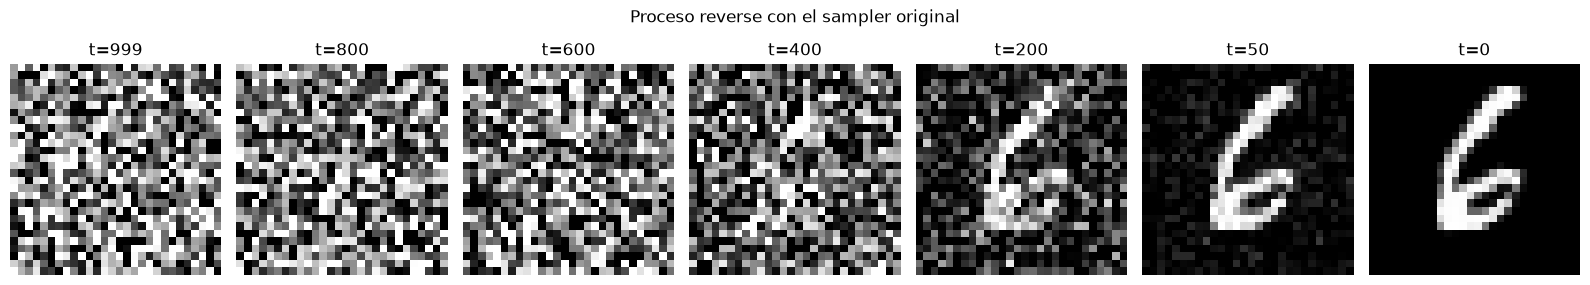

In [59]:
steps = [
    999,
    800,
    600,
    400,
    200,
    50,
    0
]

fig, axes = plt.subplots(
    1,
    len(steps),
    figsize=(16, 3)
)

for ax, timestep in zip(
    axes,
    steps
):

    image = snapshots[timestep][0]

    # Igual que en tu código original
    image = (image + 1) / 2
    image = image.clamp(0, 1)

    ax.imshow(
        image.squeeze(),
        cmap="gray"
    )

    ax.set_title(
        f"t={timestep}"
    )

    ax.axis("off")

plt.suptitle(
    "Proceso reverse con el sampler original"
)

plt.tight_layout()

plt.show()

Tiempos guardados: [999, 750, 500, 250, 50, 0]


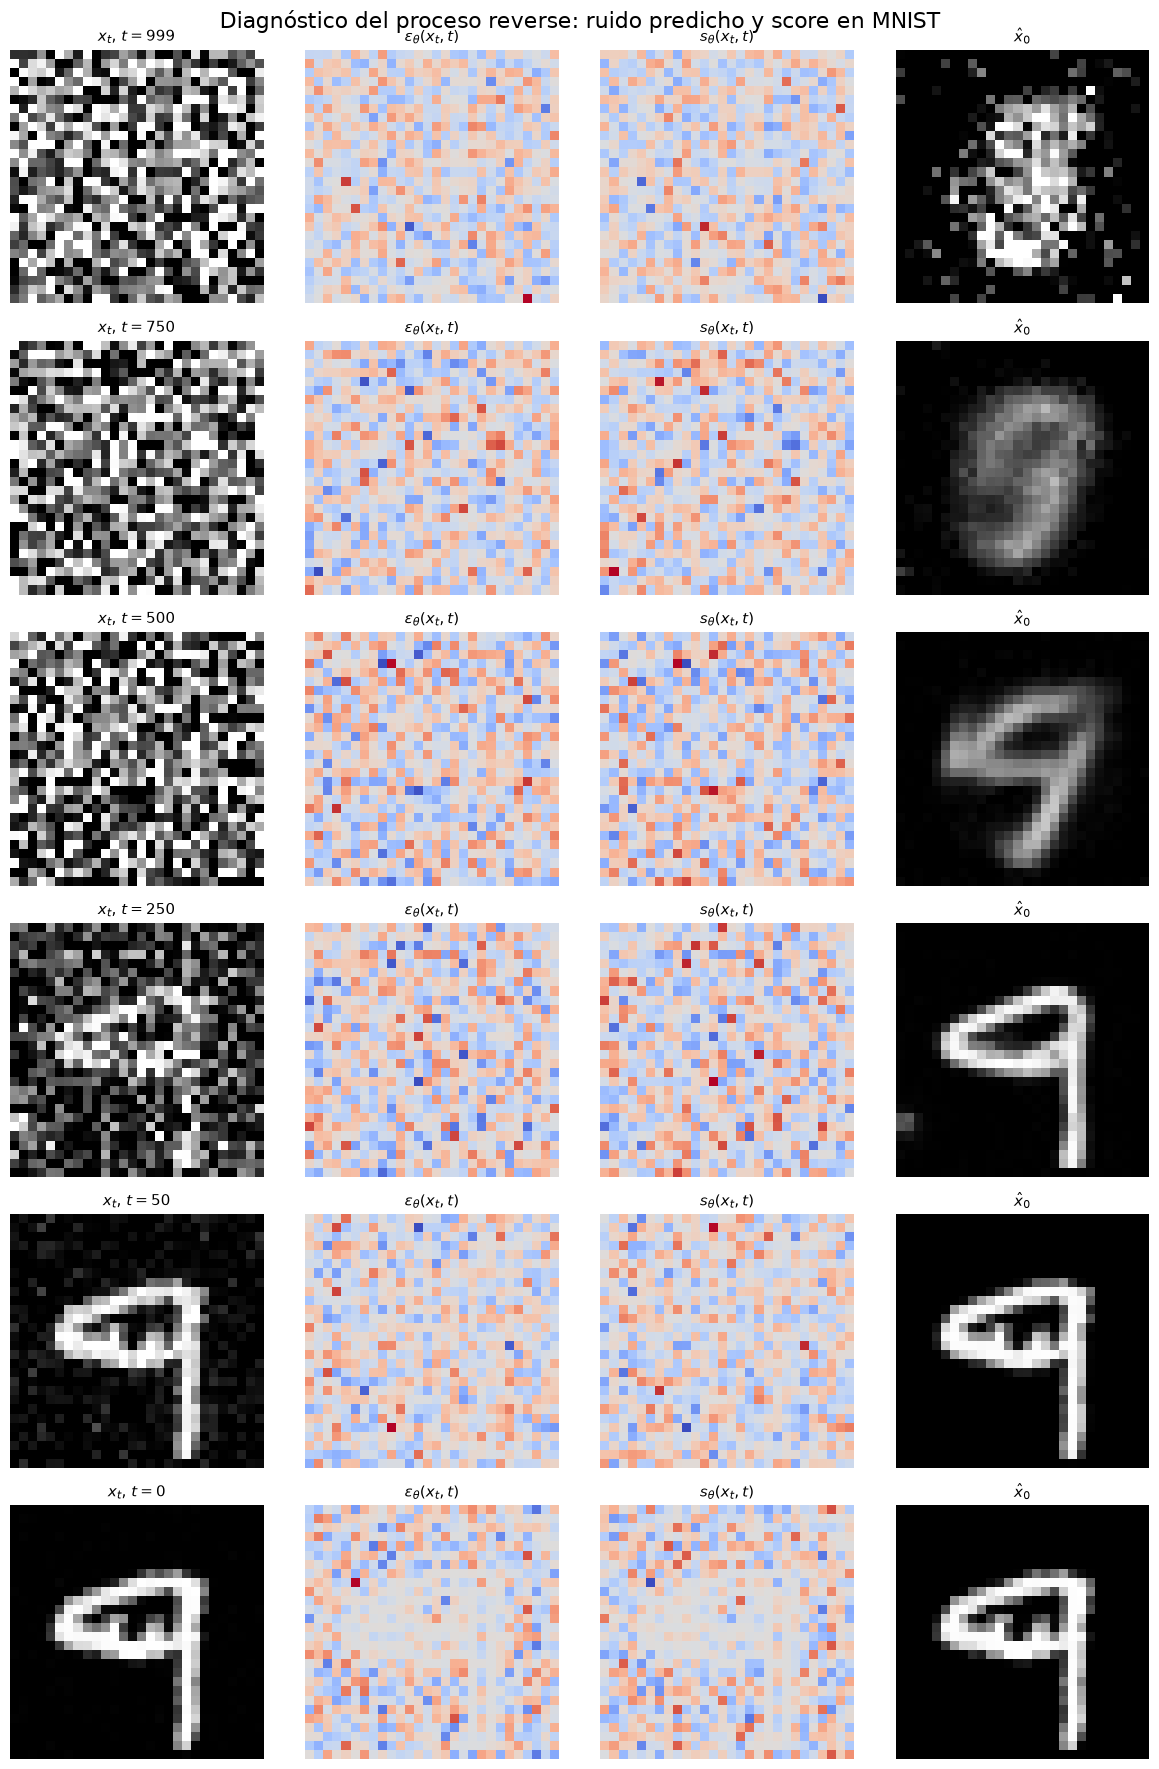

In [60]:
# ============================================================
# VISUALIZAR EL SCORE DURANTE UNA TRAYECTORIA REVERSE EN MNIST
# ============================================================

# ------------------------------------------------------------
# 1. ASEGURAR QUE EL MODELO ESTÉ EN EVALUACIÓN
# ------------------------------------------------------------

model.eval()

# ------------------------------------------------------------
# 2. TIEMPOS QUE QUEREMOS GUARDAR
# ------------------------------------------------------------

save_times = [999, 750, 500, 250, 50, 0]

# ------------------------------------------------------------
# 3. FUNCIONES AUXILIARES
# ------------------------------------------------------------

def show_gray(ax, tensor, title):
    image = tensor.squeeze().detach().cpu().numpy()

    # MNIST está normalizado aproximadamente entre -1 y 1
    image = np.clip(image, -1, 1)

    ax.imshow(image, cmap="gray", vmin=-1, vmax=1)
    ax.set_title(title, fontsize=11)
    ax.axis("off")


def show_signed(ax, tensor, title):
    image = tensor.squeeze().detach().cpu().numpy()

    max_abs = np.max(np.abs(image))
    if max_abs < 1e-8:
        max_abs = 1.0

    im = ax.imshow(
        image,
        cmap="coolwarm",
        vmin=-max_abs,
        vmax=max_abs
    )
    ax.set_title(title, fontsize=11)
    ax.axis("off")
    return im


# ------------------------------------------------------------
# 4. FUNCIÓN PARA GUARDAR EL PROCESO REVERSE CON DIAGNÓSTICO
# ------------------------------------------------------------

def reverse_process_with_score_diagnostics(
    model,
    betas,
    alphas,
    alpha_bar,
    device,
    save_times,
    image_shape=(1, 1, 28, 28)
):
    """
    Genera una sola trayectoria reverse desde ruido gaussiano
    y guarda, en ciertos tiempos t:
      - x_t
      - epsilon_theta(x_t, t)
      - score estimado
      - x0_hat
    """

    T = len(betas)

    # Empezamos desde ruido puro: x_T ~ N(0, I)
    x = torch.randn(image_shape, device=device)

    saved_results = []

    for t in reversed(range(T)):
        t_tensor = torch.full(
            (image_shape[0],),
            t,
            dtype=torch.long,
            device=device
        )

        beta_t = betas[t]
        alpha_t = alphas[t]
        alpha_bar_t = alpha_bar[t]

        with torch.no_grad():
            epsilon_pred = model(x, t_tensor)

        # Score estimado:
        # s_theta(x_t,t) = - epsilon_theta(x_t,t) / sqrt(1 - alpha_bar_t)
        score_pred = -epsilon_pred / torch.sqrt(1.0 - alpha_bar_t)

        # Reconstrucción estimada de x0
        x0_hat = (
            x - torch.sqrt(1.0 - alpha_bar_t) * epsilon_pred
        ) / torch.sqrt(alpha_bar_t)

        # Guardar diagnóstico si este t está en los tiempos deseados
        if t in save_times:
            saved_results.append({
                "t": t,
                "xt": x.detach().cpu().clone(),
                "epsilon_pred": epsilon_pred.detach().cpu().clone(),
                "score_pred": score_pred.detach().cpu().clone(),
                "x0_hat": x0_hat.detach().cpu().clone()
            })

        # Paso reverse del DDPM
        if t > 0:
            z = torch.randn_like(x)
        else:
            z = torch.zeros_like(x)

        mu_theta = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            x - ((1.0 - alpha_t) / torch.sqrt(1.0 - alpha_bar_t)) * epsilon_pred
        )

        sigma_t = torch.sqrt(beta_t)

        x = mu_theta + sigma_t * z

    # Ordenar los resultados de mayor t a menor t
    saved_results = sorted(saved_results, key=lambda d: d["t"], reverse=True)

    return saved_results


# ------------------------------------------------------------
# 5. EJECUTAR LA TRAYECTORIA
# ------------------------------------------------------------

results = reverse_process_with_score_diagnostics(
    model=model,
    betas=betas,
    alphas=alphas,
    alpha_bar=alpha_bar,   # si en tu código se llama alpha_bars, cambia esto
    device=device,
    save_times=save_times,
    image_shape=(1, 1, 28, 28)
)

print("Tiempos guardados:", [r["t"] for r in results])

# ------------------------------------------------------------
# 6. GRAFICAR
# ------------------------------------------------------------

n_rows = len(results)
n_cols = 4

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(12, 3 * n_rows)
)

# Si solo hay una fila, axes no sale como matriz 2D
if n_rows == 1:
    axes = np.expand_dims(axes, axis=0)

for i, result in enumerate(results):
    t = result["t"]

    # x_t
    show_gray(
        axes[i, 0],
        result["xt"],
        rf"$x_t$, $t={t}$"
    )

    # epsilon predicho
    show_signed(
        axes[i, 1],
        result["epsilon_pred"],
        r"$\epsilon_\theta(x_t,t)$"
    )

    # score estimado
    show_signed(
        axes[i, 2],
        result["score_pred"],
        r"$s_\theta(x_t,t)$"
    )

    # x0 estimado
    show_gray(
        axes[i, 3],
        result["x0_hat"],
        r"$\hat{x}_0$"
    )

plt.suptitle(
    "Diagnóstico del proceso reverse: ruido predicho y score en MNIST",
    fontsize=16
)

plt.tight_layout()
plt.show()

Tiempos guardados: [999, 750, 500, 250, 50, 0]


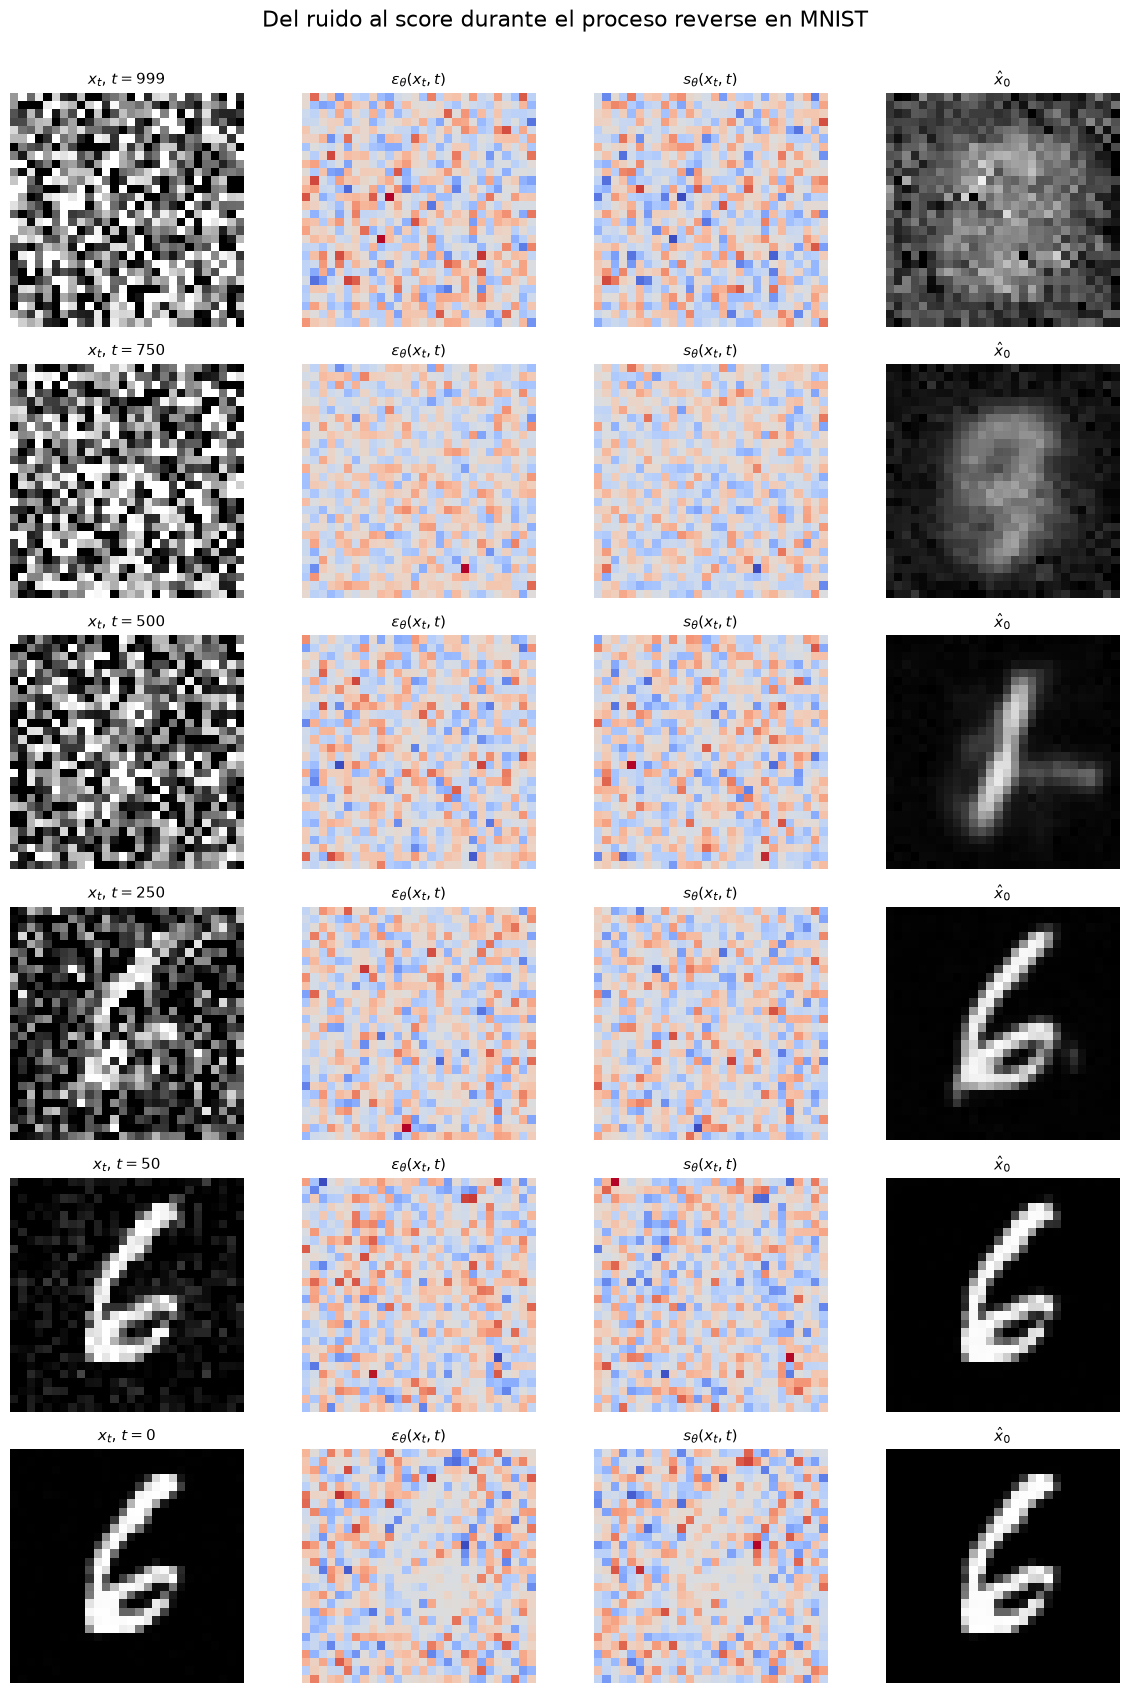

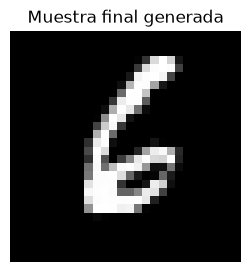

In [61]:
# ============================================================
# 1. MODELO EN MODO EVALUACIÓN
# ============================================================

model.eval()


# ============================================================
# 2. COMPATIBILIDAD CON EL NOMBRE DE alpha_bar
#
# En algunos notebooks usamos "alpha_bar"
# y en el archivo original se llama "alpha_bars".
# ============================================================

if "alpha_bar" in globals():

    alpha_bar_values = alpha_bar

elif "alpha_bars" in globals():

    alpha_bar_values = alpha_bars

else:

    raise NameError(
        "No encuentro ni 'alpha_bar' ni 'alpha_bars'."
    )


# ============================================================
# 3. TIEMPOS QUE QUEREMOS OBSERVAR
# ============================================================

save_times = [
    999,
    750,
    500,
    250,
    50,
    0
]


# ============================================================
# 4. SEMILLA
#
# Esto permite repetir exactamente la misma trayectoria
# si vuelves a ejecutar la celda.
# ============================================================

torch.manual_seed(42)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(42)


# ============================================================
# 5. FUNCIÓN DEL PROCESO REVERSE + DIAGNÓSTICO DEL SCORE
# ============================================================

@torch.no_grad()
def reverse_process_with_score_diagnostics(
    model,
    n_samples=1
):

    model.eval()

    # --------------------------------------------------------
    # Empezamos desde ruido gaussiano puro:
    #
    # x_T ~ N(0, I)
    # --------------------------------------------------------

    x = torch.randn(
        n_samples,
        1,
        28,
        28,
        device=device
    )


    results = []


    # ========================================================
    # RECORRER EL PROCESO REVERSE
    # ========================================================

    for timestep in reversed(range(T)):

        # ----------------------------------------------------
        # Tensor temporal
        # ----------------------------------------------------

        t_tensor = torch.full(
            (n_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )


        # ----------------------------------------------------
        # Parámetros de difusión en este instante
        # ----------------------------------------------------

        beta_t = betas[timestep]

        alpha_t = alphas[timestep]

        alpha_bar_t = alpha_bar_values[
            timestep
        ]


        # ====================================================
        # A. LA U-NET PREDICE EL RUIDO
        # ====================================================

        epsilon_pred = model(
            x,
            t_tensor
        )


        # ====================================================
        # B. CALCULAR EL SCORE
        #
        # s_theta(x_t,t)
        #
        # =
        #
        # - epsilon_theta(x_t,t)
        # ----------------------
        # sqrt(1-alpha_bar_t)
        # ====================================================

        score_pred = (
            -epsilon_pred
            /
            torch.sqrt(
                1.0 - alpha_bar_t
            )
        )


        # ====================================================
        # C. ESTIMACIÓN INSTANTÁNEA DE x_0
        #
        # Esto NO es todavía el resultado final del reverse.
        #
        # x0_hat =
        #
        # x_t - sqrt(1-alpha_bar_t) epsilon_theta
        # ----------------------------------------
        # sqrt(alpha_bar_t)
        # ====================================================

        x0_hat = (
            x
            -
            torch.sqrt(
                1.0 - alpha_bar_t
            )
            *
            epsilon_pred
        ) / torch.sqrt(
            alpha_bar_t
        )


        # ====================================================
        # D. GUARDAR DIAGNÓSTICO
        #
        # Guardamos x_t ANTES de pasar a x_{t-1}.
        # ====================================================

        if timestep in save_times:

            results.append({

                "t": timestep,

                "xt":
                    x.detach()
                    .cpu()
                    .clone(),

                "epsilon_pred":
                    epsilon_pred.detach()
                    .cpu()
                    .clone(),

                "score_pred":
                    score_pred.detach()
                    .cpu()
                    .clone(),

                "x0_hat":
                    x0_hat.detach()
                    .cpu()
                    .clone()
            })


        # ====================================================
        # E. PASO REVERSE
        #
        # Esta parte coincide con tu sampler original.
        # ====================================================

        mean = (
            1.0
            /
            torch.sqrt(
                alpha_t
            )
        ) * (

            x

            -

            beta_t
            /
            torch.sqrt(
                1.0 - alpha_bar_t
            )
            *
            epsilon_pred
        )


        # ----------------------------------------------------
        # Si t > 0:
        # añadimos el término estocástico.
        # ----------------------------------------------------

        if timestep > 0:

            alpha_bar_previous = (
                alpha_bar_values[
                    timestep - 1
                ]
            )


            # Varianza posterior:
            #
            # beta_tilde_t =
            #
            # beta_t (1-alpha_bar_{t-1})
            # --------------------------
            #       1-alpha_bar_t
            #

            posterior_variance = (

                beta_t

                *

                (
                    1.0
                    -
                    alpha_bar_previous
                )

                /

                (
                    1.0
                    -
                    alpha_bar_t
                )
            )


            z = torch.randn_like(
                x
            )


            x = (
                mean
                +
                torch.sqrt(
                    posterior_variance
                )
                *
                z
            )


        # ----------------------------------------------------
        # En t = 0 no añadimos ruido
        # ----------------------------------------------------

        else:

            x = mean


    # ========================================================
    # Resultado final generado
    # ========================================================

    final_image = (
        x.detach()
        .cpu()
        .clone()
    )


    # Ordenar desde t grande hasta t pequeño
    results = sorted(
        results,
        key=lambda result: result["t"],
        reverse=True
    )


    return results, final_image


# ============================================================
# 6. EJECUTAR EL PROCESO
# ============================================================

results, final_image = (
    reverse_process_with_score_diagnostics(
        model,
        n_samples=1
    )
)


print(
    "Tiempos guardados:",
    [result["t"] for result in results]
)


# ============================================================
# 7. FUNCIONES DE VISUALIZACIÓN
# ============================================================

def show_xt(
    ax,
    tensor,
    title
):

    image = (
        tensor
        .squeeze()
        .numpy()
    )

    # MNIST fue normalizado a [-1,1]
    image = np.clip(
        image,
        -1,
        1
    )

    ax.imshow(
        image,
        cmap="gray",
        vmin=-1,
        vmax=1
    )

    ax.set_title(
        title,
        fontsize=11
    )

    ax.axis(
        "off"
    )


# ------------------------------------------------------------
# Para epsilon y score:
# valores positivos y negativos
# ------------------------------------------------------------

def show_signed(
    ax,
    tensor,
    title
):

    image = (
        tensor
        .squeeze()
        .numpy()
    )


    max_abs = np.max(
        np.abs(image)
    )


    if max_abs < 1e-8:

        max_abs = 1.0


    ax.imshow(
        image,
        cmap="coolwarm",
        vmin=-max_abs,
        vmax=max_abs
    )


    ax.set_title(
        title,
        fontsize=11
    )


    ax.axis(
        "off"
    )


# ------------------------------------------------------------
# Para x0_hat:
#
# no hacemos clip inmediato a [-1,1],
# porque en t grande puede tener valores muy grandes.
#
# Usamos una escala robusta.
# ------------------------------------------------------------

def show_x0_hat(
    ax,
    tensor,
    title
):

    image = (
        tensor
        .squeeze()
        .numpy()
    )


    scale = np.percentile(
        np.abs(image),
        98
    )


    if scale < 1e-8:

        scale = 1.0


    ax.imshow(
        image,
        cmap="gray",
        vmin=-scale,
        vmax=scale
    )


    ax.set_title(
        title,
        fontsize=11
    )


    ax.axis(
        "off"
    )


# ============================================================
# 8. FIGURA PRINCIPAL
# ============================================================

n_rows = len(
    results
)

n_cols = 4


fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(
        12,
        2.8 * n_rows
    )
)


for i, result in enumerate(
    results
):

    timestep = result["t"]


    # --------------------------------------------------------
    # Columna 1:
    # estado actual x_t
    # --------------------------------------------------------

    show_xt(
        axes[i, 0],
        result["xt"],
        rf"$x_t$, $t={timestep}$"
    )


    # --------------------------------------------------------
    # Columna 2:
    # ruido predicho
    # --------------------------------------------------------

    show_signed(
        axes[i, 1],
        result["epsilon_pred"],
        r"$\epsilon_\theta(x_t,t)$"
    )


    # --------------------------------------------------------
    # Columna 3:
    # score estimado
    # --------------------------------------------------------

    show_signed(
        axes[i, 2],
        result["score_pred"],
        r"$s_\theta(x_t,t)$"
    )


    # --------------------------------------------------------
    # Columna 4:
    # estimación instantánea de x_0
    # --------------------------------------------------------

    show_x0_hat(
        axes[i, 3],
        result["x0_hat"],
        r"$\hat{x}_0$"
    )


plt.suptitle(
    "Del ruido al score durante el proceso reverse en MNIST",
    fontsize=16,
    y=1.005
)


plt.tight_layout()

plt.show()


# ============================================================
# 9. MOSTRAR LA IMAGEN FINAL GENERADA
# ============================================================

image_final = (
    final_image[0]
    .squeeze()
    .numpy()
)


image_final = (
    image_final
    +
    1
) / 2


image_final = np.clip(
    image_final,
    0,
    1
)


plt.figure(
    figsize=(3, 3)
)


plt.imshow(
    image_final,
    cmap="gray"
)


plt.title(
    "Muestra final generada"
)


plt.axis(
    "off"
)


plt.show()